# Single-cell RNA-seq of clear cell renal cell carcinoma: tumor cells vs. normal proximal tubule

Public data: GEO [GSE159115](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE159115) (10x Genomics, 7 ccRCC and 6 benign kidney samples used here).

**Pipeline:** load matrices, quality control, doublet removal, normalization and PCA, Harmony integration, clustering, cell-type annotation, pseudobulk differential expression (PyDESeq2), paired sensitivity analysis, Hallmark gene set enrichment (GSEA).

Run all cells top to bottom in Google Colab. Final outputs are saved as CSV and PNG files in the working folder.

## 0. Setup

In [1]:
!pip install -q scanpy scrublet harmonypy leidenalg gseapy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 15.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 53.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 239.0/239.0 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 13.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 75.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 105.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 30.8 MB/s eta 0:00:00
   ━━━━

## 1. Download data from GEO

Count matrices (HDF5) for all samples plus the original authors' per-cell annotation, which is used later as a reference for QC and annotation.

In [2]:
!mkdir -p data && cd data && \
wget -q -O GSE159115_RAW.tar "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE159115&format=file" && \
wget -q -O ccRCC_anno.csv.gz "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE159115&format=file&file=GSE159115%5FccRCC%5Fanno%2Ecsv%2Egz" && \
wget -q -O normal_anno.csv.gz "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE159115&format=file&file=GSE159115%5Fnormal%5Fanno%2Ecsv%2Egz" && \
tar -xf GSE159115_RAW.tar
!ls -lh data

total 232M
-rw-r--r-- 1 root root 906K Sep 23  2022 ccRCC_anno.csv.gz
-rw-r--r-- 1 root root 115M Feb  1  2024 GSE159115_RAW.tar
-rw-r--r-- 1 root root 8.1M Oct  3  2020 GSM4819725_SI_18854_filtered_gene_bc_matrices_h5.h5
-rw-r--r-- 1 root root 3.9M Oct  3  2020 GSM4819726_SI_18856_filtered_gene_bc_matrices_h5.h5
-rw-r--r-- 1 root root 6.3M Oct  3  2020 GSM4819727_SI_18855_filtered_gene_bc_matrices_h5.h5
-rw-r--r-- 1 root root 3.2M Oct  3  2020 GSM4819728_SI_19704_filtered_gene_bc_matrices_h5.h5
-rw-r--r-- 1 root root  13M Oct  3  2020 GSM4819729_SI_19703_filtered_gene_bc_matrices_h5.h5
-rw-r--r-- 1 root root 2.5M Oct  3  2020 GSM4819730_SI_21255_filtered_gene_bc_matrices_h5.h5
-rw-r--r-- 1 root root 2.0M Oct  3  2020 GSM4819731_SI_21256_filtered_gene_bc_matrices_h5.h5
-rw-r--r-- 1 root root  13M Oct  3  2020 GSM4819732_SI_21561_filtered_gene_bc_matrices_h5.h5
-rw-r--r-- 1 root root 2.7M Oct  3  2020 GSM4819733_SI_22369_filtered_gene_bc_matrices_h5.h5
-rw-r--r-- 1 root root 5.0M Oct  3

Preview of the authors' annotation tables (tumor and normal).

In [3]:
import pandas as pd
cc = pd.read_csv("data/ccRCC_anno.csv.gz")
nm = pd.read_csv("data/normal_anno.csv.gz")
print(cc.head(), cc.shape)
print(nm.head(), nm.shape)

                          cell  total_UMI  no_genes    pct_MT    sample  \
0  SI_18854_AAACCTGCAAGTAGTA-1      11582      3255  0.074599  SI_18854   
1  SI_18854_AAACCTGTCCACTGGG-1      17871      3807  0.136646  SI_18854   
2  SI_18854_AAACCTGTCCTTTCTC-1      10418      2770  0.110290  SI_18854   
3  SI_18854_AAACGGGCAAACTGCT-1      12433      2185  0.041502  SI_18854   
4  SI_18854_AAACGGGCAAGGTTTC-1      11481      2741  0.051302  SI_18854   

   gene_per_1kUMI  no_genes_log10  cellfilt  doublet_score  doublet  cluster  \
0      281.039544        3.512551     False       0.014558    False        1   
1      213.026691        3.580583     False       0.022601    False        1   
2      265.885967        3.442480     False       0.044095    False        1   
3      175.741977        3.339451     False       0.008371    False        6   
4      238.742270        3.437909     False       0.024152    False        1   

    anno    label  patient  
0  Tumor  1:Tumor  SS_2005  
1  Tumor  

## Sample overview

Samples, patients and cell counts per group, and the authors' cell-type labels.

In [4]:
cc_s = cc.groupby(['sample','patient']).size().rename('n_cells').reset_index().assign(group='ccRCC')
nm_s = nm.groupby(['sample','patient']).size().rename('n_cells').reset_index().assign(group='normal')
meta = pd.concat([cc_s, nm_s], ignore_index=True)
print(meta)
print(cc['anno'].value_counts())
print(nm['anno'].value_counts())
print(cc['cellfilt'].value_counts())
print(cc['doublet'].value_counts())

      sample  patient  n_cells   group
0   SI_18854  SS_2005     1665   ccRCC
1   SI_18855  SS_2006     1362   ccRCC
2   SI_19703  SS_2007     3331   ccRCC
3   SI_22368  SS_2017     2808   ccRCC
4   SI_22604  SS_2022     1923   ccRCC
5   SI_23459  SS_2023     6108   ccRCC
6   SI_23843  SS_2026     3551   ccRCC
7   SI_18856  SS_2006      736  normal
8   SI_19704  SS_2007      689  normal
9   SI_21255  SS_2014     1020  normal
10  SI_21256  SS_2014      551  normal
11  SI_22369  SS_2017     1504  normal
12  SI_22605  SS_2022     1646  normal
anno
Tumor          9139
Macro          4149
Endo_PLVAP     2573
vSMC           2119
Tcell           960
Peri            589
Endo_ACKR1      487
ua              239
Tcell_CD8       207
Plasma          116
Bcell            69
Mast             64
Macro_MKI67      37
Name: count, dtype: int64
anno
PT-A         1941
AVR           497
TAL           483
IC-A          397
DCT           275
AEA-DVR       264
Macro         262
GC            235
Tcell         

## 2. Load and merge samples

Each sample is read separately, cell names get a sample prefix, and sample, patient and group labels are stored in `adata.obs`.

In [5]:
import scanpy as sc, anndata as ad, glob

adatas = []
for _, r in meta.iterrows():
    f = glob.glob(f"data/*_{r['sample']}_filtered_gene_bc_matrices_h5.h5")[0]
    a = sc.read_10x_h5(f)
    a.var_names_make_unique()
    a.obs_names = [f"{r['sample']}_{b}" for b in a.obs_names]
    a.obs['sample'] = r['sample']
    a.obs['patient'] = r['patient']
    a.obs['group'] = r['group']
    adatas.append(a)

adata = ad.concat(adatas, join='inner')
adata.obs_names_make_unique()
print(adata)
print(adata.obs.groupby(['group','sample']).size())

anno_all = pd.concat([cc, nm]).set_index('cell')
print("cells from h5 that are in the authors' annotation:", adata.obs_names.isin(anno_all.index).sum())

/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:362: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = AnnData(
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:362: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = AnnData(
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:362: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = AnnData(
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:362: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = AnnData(
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:362: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = AnnData(
/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:362: UserWarning: Variable names are not

AnnData object with n_obs × n_vars = 29499 × 33694
    obs: 'sample', 'patient', 'group'
    layers: None (.X)
group   sample  
ccRCC   SI_18854    1704
        SI_18855    1660
        SI_19703    3674
        SI_22368    2872
        SI_22604    1953
        SI_23459    6453
        SI_23843    3635
normal  SI_18856    1410
        SI_19704     923
        SI_21255    1097
        SI_21256     578
        SI_22369    1644
        SI_22605    1896
dtype: int64
cells from h5 that are in the authors' annotation: 26894


## 3. Quality control

Mitochondrial fraction, genes per cell and counts per cell. Cells that the authors removed are marked in `in_authors`, which lets us compare our QC thresholds with theirs.

        total_counts  n_genes_by_counts  pct_counts_mt
group                                                 
ccRCC         7188.0             2149.0       3.417518
normal        5094.5             1289.0      12.147759
            total_counts  n_genes_by_counts  pct_counts_mt
in_authors                                                
False             5926.0              571.0      82.147736
True              6679.0             2044.0       3.534514


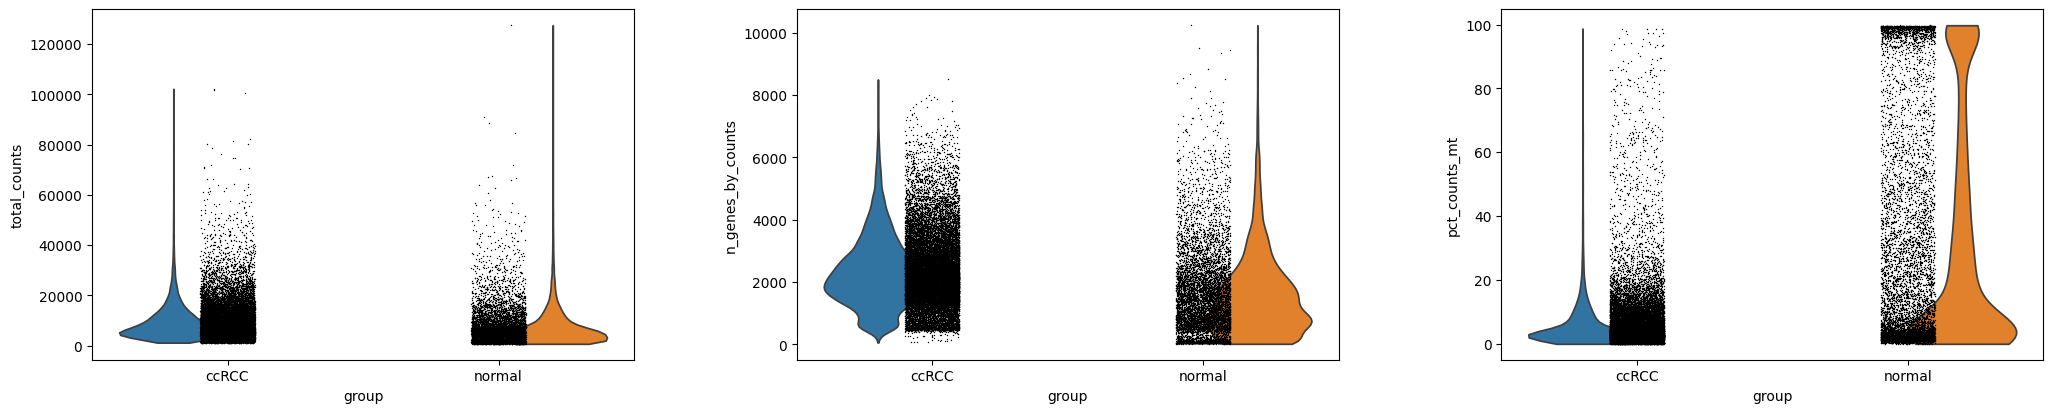

In [6]:
adata.var['mt'] = adata.var_names.str.startswith('MT-')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, log1p=False, inplace=True)

adata.obs['in_authors'] = adata.obs_names.isin(anno_all.index)

cols = ['total_counts', 'n_genes_by_counts', 'pct_counts_mt']
print(adata.obs.groupby('group')[cols].median())
print(adata.obs.groupby('in_authors')[cols].median())

sc.pl.violin(adata, cols, groupby='group', multi_panel=True)

                   total_counts  n_genes_by_counts  pct_counts_mt
group  in_authors                                                
ccRCC  False             6840.0             1821.0      28.564941
       True              7205.5             2158.0       3.287388
normal False             5540.5              114.0      97.326569
       True              4970.0             1559.0       6.398267
sample
SI_18854    0.98
SI_18855    0.82
SI_18856    0.52
SI_19703    0.91
SI_19704    0.75
SI_21255    0.93
SI_21256    0.95
SI_22368    0.98
SI_22369    0.91
SI_22604    0.98
SI_22605    0.87
SI_23459    0.95
SI_23843    0.98
Name: in_authors, dtype: float64
authors' pct_MT (fraction, not %):
ccRCC: [0.007, 0.033, 0.116]
normal: [0.013, 0.064, 0.489]


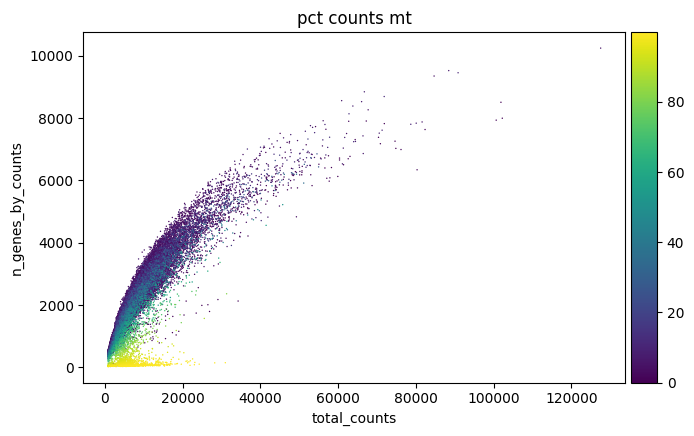

In [7]:
print(adata.obs.groupby(['group','in_authors'])[cols].median())
print(adata.obs.groupby('sample')['in_authors'].mean().round(2))

print("authors' pct_MT (fraction, not %):")
print("ccRCC:", cc['pct_MT'].quantile([.1,.5,.9]).round(3).tolist())
print("normal:", nm['pct_MT'].quantile([.1,.5,.9]).round(3).tolist())

sc.pl.scatter(adata, 'total_counts', 'n_genes_by_counts', color='pct_counts_mt')

Distribution of the authors' own QC values (minimum genes, maximum mitochondrial fraction), per group.

In [8]:
for name, d in [('ccRCC', cc), ('normal', nm)]:
    print(name)
    print(d[['total_UMI', 'no_genes', 'pct_MT']].describe().round(3))

ccRCC
        total_UMI   no_genes     pct_MT
count   20748.000  20748.000  20748.000
mean     9252.975   2340.431      0.049
std      7350.077   1119.756      0.046
min      1240.000    369.000      0.000
25%      4592.750   1591.750      0.020
50%      7205.500   2158.000      0.033
75%     11714.250   2901.000      0.064
max    102229.000   8505.000      0.250
normal
        total_UMI   no_genes    pct_MT
count    6146.000   6146.000  6146.000
mean     7393.015   1862.949     0.166
std      8206.329   1292.449     0.197
min       780.000    302.000     0.000
25%      2271.250    895.000     0.024
50%      4970.000   1559.000     0.064
75%      8909.000   2371.750     0.260
max    127538.000  10243.000     0.800


**First QC attempt:** genes per cell ≥ 300; mitochondrial fraction ≤ 25% in tumor and ≤ 50% in normal tissue.

In [9]:
import pandas as pd

mt = adata.obs['pct_counts_mt']
ng = adata.obs['n_genes_by_counts']
is_t = adata.obs['group'] == 'ccRCC'

keep = (ng >= 300) & ((is_t & (mt <= 25)) | (~is_t & (mt <= 50)))
adata.obs['keep_ours'] = keep

print(keep.sum(), "of", adata.n_obs)
print(pd.crosstab(adata.obs['keep_ours'], adata.obs['in_authors']))
print(adata.obs.groupby('sample')['keep_ours'].mean().round(2))

26864 of 29499
in_authors  False  True 
keep_ours               
False        2058    577
True          547  26317
sample
SI_18854    0.99
SI_18855    0.83
SI_18856    0.42
SI_19703    0.92
SI_19704    0.57
SI_21255    0.90
SI_21256    0.93
SI_22368    0.99
SI_22369    0.89
SI_22604    1.00
SI_22605    0.81
SI_23459    0.98
SI_23843    1.00
Name: keep_ours, dtype: float64


**Check:** which cells did this threshold remove that the authors kept? They are all from normal samples and mostly tubule cells, which are naturally rich in mitochondria.

In [10]:
lost = adata.obs[(~adata.obs['keep_ours']) & adata.obs['in_authors']]

print(lost['group'].value_counts())

lost_types = anno_all.loc[lost.index, 'anno'].value_counts()
tot_types = anno_all['anno'].value_counts()

print(lost_types.head(10))
print((lost_types / tot_types).dropna().sort_values(ascending=False).head(10).round(2))

group
normal    577
ccRCC       0
Name: count, dtype: int64
anno
PT-A     156
TAL      154
DCT      105
IC-A      52
CNT       30
PC        23
PT-B      17
ua        14
IC-PC     10
PT-C       4
Name: count, dtype: int64
anno
DCT      0.38
TAL      0.32
CNT      0.24
PC       0.20
IC-A     0.13
PT-B     0.12
PT-C     0.09
PT-A     0.08
IC-PC    0.08
IC-B     0.06
Name: count, dtype: float64


**Final QC:** the mitochondrial limit for normal tissue is raised to 80%. All 26,894 cells from the authors' filtered annotation are retained. Genes found in fewer than 3 cells are dropped.

In [11]:
keep = (ng >= 300) & ((is_t & (mt <= 25)) | (~is_t & (mt <= 80)))
adata.obs['keep_ours'] = keep

print(keep.sum(), "of", adata.n_obs)
print(pd.crosstab(adata.obs['keep_ours'], adata.obs['in_authors']))

adata = adata[adata.obs['keep_ours']].copy()
sc.pp.filter_genes(adata, min_cells=3)
print(adata)

27458 of 29499
in_authors  False  True 
keep_ours               
False        2041      0
True          564  26894
AnnData object with n_obs × n_vars = 27458 × 25183
    obs: 'sample', 'patient', 'group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'in_authors', 'keep_ours'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'group_colors'
    layers: None (.X)


## 4. Doublet detection (Scrublet, per sample)

In [12]:
sc.pp.scrublet(adata, batch_key='sample')

print(adata.obs['predicted_doublet'].value_counts())
print(adata.obs.groupby('sample')['predicted_doublet'].mean().round(3))
print(pd.crosstab(adata.obs['predicted_doublet'], adata.obs['in_authors']))

predicted_doublet
False    27166
True       292
Name: count, dtype: int64
sample
SI_18854    0.002
SI_18855    0.005
SI_18856    0.003
SI_19703    0.012
SI_19704    0.006
SI_21255    0.003
SI_21256    0.002
SI_22368    0.001
SI_22369    0.003
SI_22604    0.005
SI_22605    0.002
SI_23459    0.020
SI_23843    0.022
Name: predicted_doublet, dtype: float64
in_authors         False  True 
predicted_doublet              
False                328  26838
True                 236     56


## 5. Normalization, highly variable genes, PCA

Doublets are removed, raw counts are kept in `layers['counts']`, data are normalized to 10,000 counts per cell and log-transformed. The full normalized matrix is stored in `adata.raw` for later gene-level analysis.

27166


/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


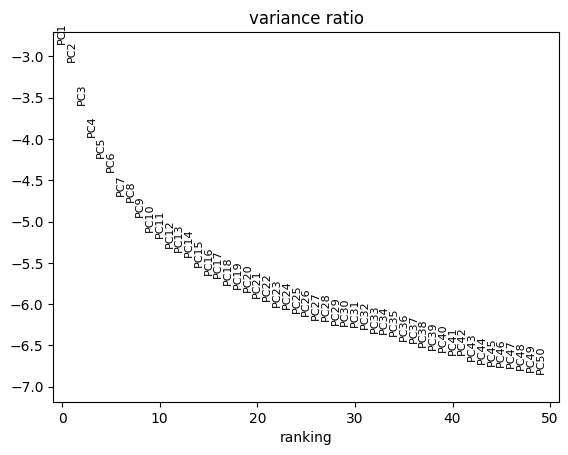

In [13]:
adata = adata[~adata.obs['predicted_doublet']].copy()
print(adata.n_obs)

adata.layers['counts'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=3000, batch_key='sample')
adata.raw = adata

adata = adata[:, adata.var['highly_variable']].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, n_comps=50)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

## 6. Batch integration with Harmony

Harmony corrects the PCA coordinates for sample effects. Expression values are not changed, so downstream DE and GSEA use the original data.

In [14]:
import harmonypy as hm

ho = hm.run_harmony(adata.obsm['X_pca'], adata.obs, 'sample', max_iter_harmony=20)
Z = ho.Z_corr
if Z.shape[0] != adata.n_obs:
    Z = Z.T
adata.obsm['X_pca_harmony'] = Z
print(Z.shape)

2026-10-19 13:29:17,524 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-10-19 13:29:17,527 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-10-19 13:29:17,529 - harmonypy - INFO -     max_iter_harmony: 20
INFO:harmonypy:    max_iter_harmony: 20
2026-10-19 13:29:17,532 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-10-19 13:29:17,536 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-10-19 13:29:17,540 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-10-19 13:29:17,541 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-10-19 13:29:17,543 - harmonypy - INFO -     block_size: 0.05
INFO:harmonypy:    block_size: 0.05
2026-10-19 13:29:17,546 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-10-19 13:29:17,549 - harmonypy - INFO -     theta: [2. 2. 2

(27166, 50)


## 7. Neighbor graph, UMAP and Leiden clustering

/tmp/ipykernel_3184/1484739500.py:3: UserWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
  sc.tl.leiden(adata, resolution=0.8, key_added='leiden', flavor='leidenalg')


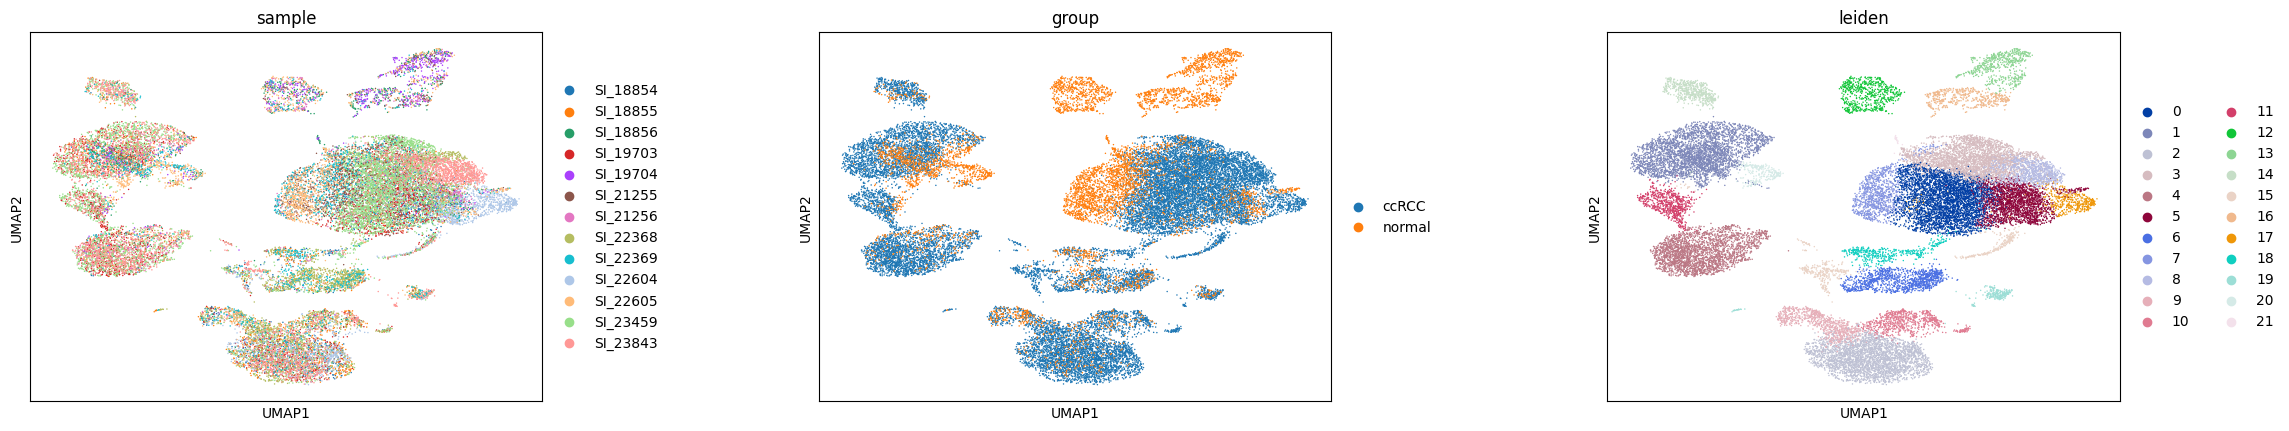

In [15]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, use_rep='X_pca_harmony')
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.8, key_added='leiden', flavor='leidenalg')
sc.pl.umap(adata, color=['sample', 'group', 'leiden'], wspace=0.4)

## 8. Cell-type annotation

The authors' labels are mapped onto our cells and used as a reference. Cell types are assigned by us from marker genes, then compared with the authors' labels.

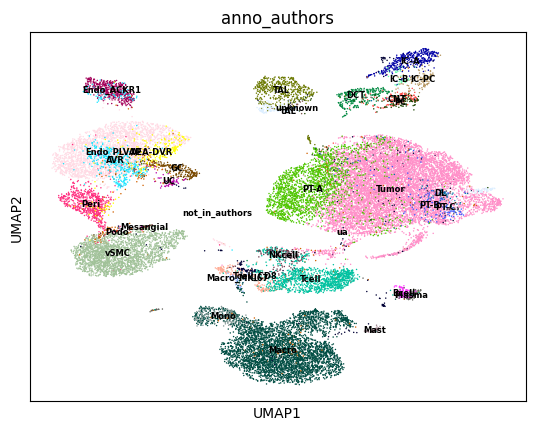

leiden
0          Tumor
1     Endo_PLVAP
2          Macro
3          Tumor
4           vSMC
5          Tumor
6          Tcell
7           PT-A
8          Tumor
9          Macro
10         Macro
11          Peri
12           TAL
13          IC-A
14    Endo_ACKR1
15         Tumor
16           DCT
17         Tumor
18         Tumor
19        Plasma
20            GC
21           TAL
dtype: category
Categories (35, str): ['AEA-DVR', 'AVR', 'Bcell', 'CNT', ..., 'tAL', 'ua', 'unknown', 'vSMC']


In [16]:
adata.obs['anno_authors'] = anno_all['anno'].reindex(adata.obs_names).values
adata.obs['anno_authors'] = adata.obs['anno_authors'].fillna('not_in_authors')

sc.pl.umap(adata, color='anno_authors', legend_loc='on data', legend_fontsize=6)

print(pd.crosstab(adata.obs['leiden'], adata.obs['anno_authors']).idxmax(axis=1))

Most frequent author label per cluster.

In [17]:
print(pd.crosstab(adata.obs['leiden'], adata.obs['anno_authors']).idxmax(axis=1).to_string())

sc.tl.rank_genes_groups(adata, groupby='leiden', method='wilcoxon', use_raw=True)
top = pd.DataFrame(adata.uns['rank_genes_groups']['names']).head(8)
print(top.T.to_string())

leiden
0          Tumor
1     Endo_PLVAP
2          Macro
3          Tumor
4           vSMC
5          Tumor
6          Tcell
7           PT-A
8          Tumor
9          Macro
10         Macro
11          Peri
12           TAL
13          IC-A
14    Endo_ACKR1
15         Tumor
16           DCT
17         Tumor
18         Tumor
19        Plasma
20            GC
21           TAL
Categories (35, str): ['AEA-DVR', 'AVR', 'Bcell', 'CNT', ..., 'tAL', 'ua', 'unknown', 'vSMC']
            0         1         2         3        4         5         6         7
0    TMEM176A  PDZK1IP1    CXCL14  TMEM176B     NAT8     BBOX1    LGALS2     CYB5A
1       RAMP2     PLPP1  SLC9A3R2      FLT1    TIMP3     GNG11    PECAM1     IFI27
2        C1QA   HLA-DRA  HLA-DPA1      C1QC   TYROBP      C1QB      CD74  HLA-DPB1
3       RPL36     CRYAB     RPL37     RPLP0     CD24      MT1E      SPP1    RPL37A
4       CALD1      MYL9      TPM2      RGS5      BGN    IGFBP7     MFGE8     PLAC9
5   TNFRSF12A     CRYAB    

Cluster purity: top three author labels per cluster with their share of cells.

In [18]:
ct = pd.crosstab(adata.obs['leiden'], adata.obs['anno_authors'])
frac = ct.div(ct.sum(axis=1), axis=0)

rows = []
for c in frac.index:
    top = frac.loc[c].sort_values(ascending=False).head(3)
    rows.append([c, int(ct.loc[c].sum())] + [f"{k} {v:.0%}" for k, v in top.items()])

print(pd.DataFrame(rows, columns=['cluster', 'cells', 'type1', 'type2', 'type3']).to_string(index=False))

cluster  cells          type1             type2             type3
      0    3830      Tumor 81%          PT-A 18%             ua 1%
      1    3315 Endo_PLVAP 76%           AVR 13%        AEA-DVR 7%
      2    3066      Macro 98% not_in_authors 1%             ua 1%
      3    2962      Tumor 87%           PT-A 9%             ua 1%
      4    2390       vSMC 96% not_in_authors 2%      Mesangial 1%
      5    1971      Tumor 83%           PT-B 6%            tAL 3%
      6    1143      Tcell 87%      Tcell_CD8 9%         NKcell 2%
      7    1001       PT-A 98%          Tumor 2% not_in_authors 0%
      8     927      Tumor 99%           PT-A 0%             ua 0%
      9     864      Macro 79%          Mono 19% not_in_authors 2%
     10     769      Macro 89%           Mast 8%             ua 2%
     11     670       Peri 89%        AEA-DVR 6% not_in_authors 4%
     12     615        TAL 75%           tAL 17%        unknown 4%
     13     582       IC-A 68%         IC-PC 21%           IC-B

Dot plot of canonical marker genes per cluster (size = fraction of cells expressing, color = relative mean expression).

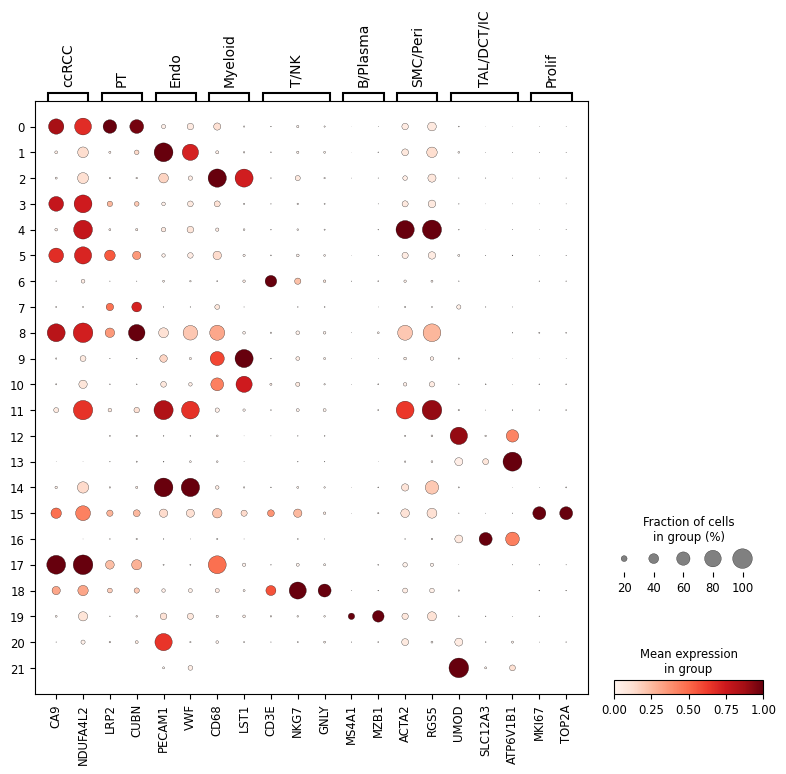

In [19]:
markers = {
    'ccRCC': ['CA9', 'NDUFA4L2'],
    'PT': ['LRP2', 'CUBN'],
    'Endo': ['PECAM1', 'VWF'],
    'Myeloid': ['CD68', 'LST1'],
    'T/NK': ['CD3E', 'NKG7', 'GNLY'],
    'B/Plasma': ['MS4A1', 'MZB1'],
    'SMC/Peri': ['ACTA2', 'RGS5'],
    'TAL/DCT/IC': ['UMOD', 'SLC12A3', 'ATP6V1B1'],
    'Prolif': ['MKI67', 'TOP2A'],
}
sc.pl.dotplot(adata, markers, groupby='leiden', use_raw=True, standard_scale='var')

Cluster names assigned from marker genes and the author labels. Several clusters can share one name.

celltype
Tumor               10169
Endothelial          4149
Macrophage           3835
vSMC                 2390
T cell               1143
PT                   1001
Monocyte/Myeloid      864
Pericyte              670
TAL                   635
IC                    582
Proliferating         537
DCT/CNT/PC            493
NK/CD8 T              444
B/Plasma              254
group             ccRCC  normal
celltype                       
B/Plasma            213      41
DCT/CNT/PC            0     493
Endothelial        3094    1055
IC                    0     582
Macrophage         3591     244
Monocyte/Myeloid    674     190
NK/CD8 T            320     124
PT                   23     978
Pericyte            598      72
Proliferating       525      12
T cell              914     229
TAL                   0     635
Tumor              8818    1351
vSMC               2171     219


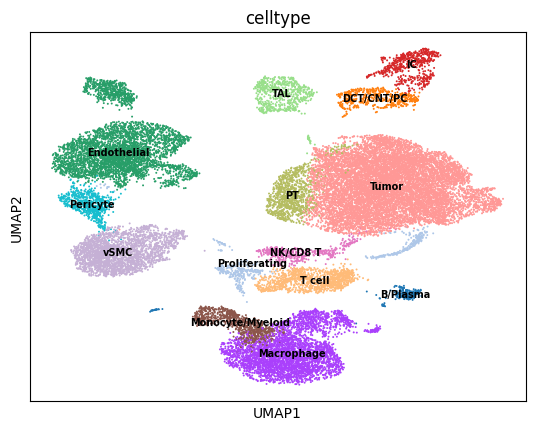

In [20]:
names = {
 '0':'Tumor','3':'Tumor','5':'Tumor','8':'Tumor','17':'Tumor',
 '1':'Endothelial','14':'Endothelial','20':'Endothelial',
 '2':'Macrophage','10':'Macrophage',
 '9':'Monocyte/Myeloid',
 '4':'vSMC','11':'Pericyte',
 '6':'T cell','18':'NK/CD8 T',
 '19':'B/Plasma',
 '7':'PT','12':'TAL','21':'TAL','13':'IC','16':'DCT/CNT/PC',
 '15':'Proliferating',
}
adata.obs['celltype'] = adata.obs['leiden'].map(names).astype('category')

print(adata.obs['celltype'].value_counts().to_string())
print(pd.crosstab(adata.obs['celltype'], adata.obs['group']).to_string())
sc.pl.umap(adata, color='celltype', legend_loc='on data', legend_fontsize=7, size=8)

**Annotation check.** Some cells from *normal* samples fell into tumor-labeled clusters (0, 3 and 5). Checking their origin and the authors' labels:

In [21]:
ct2 = pd.crosstab(adata.obs['leiden'], adata.obs['group'])
ct2['normal_%'] = (ct2['normal'] / ct2.sum(axis=1) * 100).round(0)
print(ct2.loc[['0','3','5','7','8','15','17']].to_string())

sub = adata.obs[(adata.obs['celltype'] == 'Tumor') & (adata.obs['group'] == 'normal')]
print(sub['anno_authors'].value_counts().head(8).to_string())
print(sub['sample'].value_counts().to_string())

group   ccRCC  normal  normal_%
leiden                         
0        3130     700      18.0
3        2622     340      11.0
5        1663     308      16.0
7          23     978      98.0
8         924       3       0.0
15        525      12       2.0
17        479       0       0.0
anno_authors
PT-A              959
PT-B              143
DL                 67
tAL                67
PT-C               41
ua                 23
not_in_authors     20
PC                 17
sample
SI_21255    466
SI_22369    373
SI_22605    300
SI_21256    119
SI_18856     62
SI_19704     31
SI_18854      0
SI_18855      0
SI_19703      0
SI_22368      0
SI_22604      0
SI_23459      0
SI_23843      0


These cells are mostly proximal tubule cells according to the authors, so they are relabeled PT. After this, no tumor-labeled cell comes from a normal sample.

In [22]:
t = adata.obs['celltype'].astype(str)
mask = (t == 'Tumor') & (adata.obs['group'] == 'normal')
t.loc[mask] = 'PT'
adata.obs['celltype'] = t.astype('category')

print(pd.crosstab(adata.obs['celltype'], adata.obs['group']).to_string())

group             ccRCC  normal
celltype                       
B/Plasma            213      41
DCT/CNT/PC            0     493
Endothelial        3094    1055
IC                    0     582
Macrophage         3591     244
Monocyte/Myeloid    674     190
NK/CD8 T            320     124
PT                   23    2329
Pericyte            598      72
Proliferating       525      12
T cell              914     229
TAL                   0     635
Tumor              8818       0
vSMC               2171     219


## 9. Pseudobulk

Raw counts are summed per patient within one cell type: tumor cells from ccRCC samples and proximal tubule cells from normal samples. This makes the patient, not the cell, the unit of replication. Patients with fewer than 30 cells of the type are excluded.

In [23]:
import numpy as np

counts_all = ad.concat(adatas, join='inner')
counts_all = counts_all[adata.obs_names, adata.raw.var_names].copy()

def pseudobulk(celltype, group, min_cells=30):
    m = (adata.obs['celltype'] == celltype) & (adata.obs['group'] == group)
    rows = {}
    for s, idx in adata.obs[m].groupby('patient').groups.items():
        if len(idx) >= min_cells:
            rows[s] = np.asarray(counts_all[idx].X.sum(axis=0)).ravel()
    return pd.DataFrame(rows, index=counts_all.var_names).T

pb_t = pseudobulk('Tumor', 'ccRCC')
pb_n = pseudobulk('PT', 'normal')

print(pb_t.shape, pb_n.shape)
print(pb_t.sum(axis=1).astype(int).to_string())
print(pb_n.sum(axis=1).astype(int).to_string())

(7, 25183) (5, 25183)
SS_2005    14546905
SS_2006     1682282
SS_2007     8724627
SS_2017     3244697
SS_2022    20476424
SS_2023    34824700
SS_2026    15087493
SS_2006    1319485
SS_2007     339022
SS_2014    3076714
SS_2017    1314299
SS_2022    6602754


## 10. Differential expression (PyDESeq2): tumor vs. normal PT

Design: `~condition`, 7 tumor patients vs. 5 normal patients. Genes must have at least 10 counts in at least 3 patients.

In [24]:
!pip install -q pydeseq2

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

counts = pd.concat([pb_t, pb_n]).round().astype(int)
meta_de = pd.DataFrame({
    'condition': ['tumor'] * len(pb_t) + ['normal'] * len(pb_n)
}, index=counts.index)

keep_g = (counts >= 10).sum(axis=0) >= 3
counts = counts.loc[:, keep_g]

print(counts.shape)
print(meta_de['condition'].value_counts())

dds = DeseqDataSet(counts=counts, metadata=meta_de, design="~condition")
dds.deseq2()

ds = DeseqStats(dds, contrast=["condition", "tumor", "normal"])
ds.summary()
res = ds.results_df.dropna(subset=['padj']).sort_values('padj')

print((res['padj'] < 0.05).sum(), "genes with padj < 0.05")
print(res.head(15)[['baseMean', 'log2FoldChange', 'padj']].round(3).to_string())
res.to_csv('DE_tumor_vs_PT.csv')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.6/87.6 kB 7.6 MB/s eta 0:00:00
(12, 14889)
condition
tumor     7
normal    5
Name: count, dtype: int64
Using None as control genes, passed at DeseqDataSet initialization


/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:249: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  super().__init__(X=counts.astype(int), obs=metadata)
Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 23.77 seconds.

Fitting dispersion trend curve...
... done in 0.69 seconds.

Fitting MAP dispersions...
... done in 26.11 seconds.

Fitting LFCs...
... done in 17.00 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:1332: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  self.counts_to_refit = self[:, self.var["replaced"]].copy()
Replacing 110 outlier genes.

/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:1390: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  self.counts_to_refit = self.counts_to_refit[:, ~n

Log2 fold change & Wald test p-value: condition tumor vs normal
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
FO538757.2     81.460724        0.182512  0.332476  0.548947  0.583042   
AP006222.2     75.365195        0.050370  0.449999  0.111934  0.910875   
RP4-669L17.10   4.812109        0.059838  0.875615  0.068338  0.945517   
RP11-206L10.9   9.518069       -0.295836  0.594785 -0.497383  0.618919   
LINC00115      12.628276        0.250713  0.489133  0.512565  0.608255   
...                  ...             ...       ...       ...       ...   
AL592183.1      8.747855       -0.011581  0.723923 -0.015997  0.987237   
AC007325.4     55.318842        0.421999  0.462936  0.911571  0.361995   
AC007325.2      3.219574        2.230614  1.136515  1.962680  0.049683   
AC004556.1     32.478774       -3.767107  1.041969 -3.615374       NaN   
AC240274.1     11.600638       -1.485032  0.680376 -2.182662  0.029061   

                   padj  
FO538757.2     0.7895

Volcano plot. Red/blue: adjusted p < 0.05 and |log2FC| > 1.

higher in tumor: 868  lower in tumor: 934


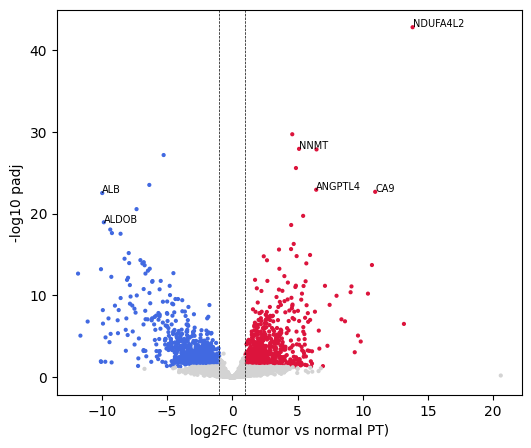

In [25]:
import matplotlib.pyplot as plt

res['nlp'] = -np.log10(res['padj'].clip(lower=1e-300))
up = (res['padj'] < 0.05) & (res['log2FoldChange'] > 1)
down = (res['padj'] < 0.05) & (res['log2FoldChange'] < -1)
print("higher in tumor:", up.sum(), " lower in tumor:", down.sum())

plt.figure(figsize=(6, 5))
plt.scatter(res['log2FoldChange'], res['nlp'], s=4,
            c=np.where(up, 'crimson', np.where(down, 'royalblue', 'lightgray')))
for g in ['CA9', 'NDUFA4L2', 'ANGPTL4', 'NNMT', 'ALB', 'ALDOB']:
    if g in res.index:
        plt.text(res.loc[g, 'log2FoldChange'], res.loc[g, 'nlp'], g, fontsize=7)
plt.axvline(1, ls='--', c='k', lw=0.5)
plt.axvline(-1, ls='--', c='k', lw=0.5)
plt.xlabel('log2FC (tumor vs normal PT)')
plt.ylabel('-log10 padj')
plt.show()

**Paired sensitivity analysis.** Only patients with both tumor and normal tissue (4 patients), design `~patient + condition`. Compared with the main analysis: number of shared significant genes and correlation of log2 fold changes.

In [26]:
paired = sorted(set(pb_t.index) & set(pb_n.index))
print(paired)

t = pb_t.loc[paired].copy(); t.index = [p + '_T' for p in paired]
n = pb_n.loc[paired].copy(); n.index = [p + '_N' for p in paired]
counts_p = pd.concat([t, n]).round().astype(int)

meta_p = pd.DataFrame({
    'condition': ['tumor'] * len(paired) + ['normal'] * len(paired),
    'patient': paired + paired,
}, index=counts_p.index)

keep_p = (counts_p >= 10).sum(axis=0) >= 3
counts_p = counts_p.loc[:, keep_p]

dds_p = DeseqDataSet(counts=counts_p, metadata=meta_p, design="~patient + condition")
dds_p.deseq2()
ds_p = DeseqStats(dds_p, contrast=["condition", "tumor", "normal"])
ds_p.summary()
res_p = ds_p.results_df.dropna(subset=['padj']).sort_values('padj')

print((res_p['padj'] < 0.05).sum(), "genes with padj < 0.05 (paired)")
both = res.index.intersection(res_p.index)
sig_u = set(res.index[res['padj'] < 0.05])
sig_p = set(res_p.index[res_p['padj'] < 0.05])
print("shared significant:", len(sig_u & sig_p))
print("log2FC correlation:", round(res.loc[both, 'log2FoldChange'].corr(res_p.loc[both, 'log2FoldChange']), 2))
print(res_p.head(10)[['baseMean', 'log2FoldChange', 'padj']].round(3).to_string())
res_p.to_csv('DE_paired.csv')

['SS_2006', 'SS_2007', 'SS_2017', 'SS_2022']
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 18.88 seconds.

Fitting dispersion trend curve...
... done in 0.51 seconds.

/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 19.43 seconds.

Fitting LFCs...
... done in 19.71 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 3.51 seconds.



Log2 fold change & Wald test p-value: condition tumor vs normal
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
FO538757.2     55.314203        0.427827  0.495199  0.863949  0.387616   
AP006222.2     46.739391       -0.060121  0.536272 -0.112110  0.910736   
RP11-206L10.9   5.159368       -0.119019  1.013260 -0.117461  0.906494   
LINC00115       8.064372        0.245932  0.823443  0.298663  0.765197   
FAM41C         12.566473       -0.843856  0.825531 -1.022198  0.306687   
...                  ...             ...       ...       ...       ...   
AC011043.1     17.590965       -0.084213  0.758944 -0.110960  0.911648   
AL592183.1      4.214019        1.300733  1.081563  1.202642  0.229115   
AC007325.4     33.710102        0.638973  0.568899  1.123174  0.261364   
AC004556.1     80.424266        0.694485  0.712423  0.974820  0.329649   
AC240274.1      9.416967       -1.839009  0.775507 -2.371364  0.017723   

                   padj  
FO538757.2     0.7388

## 11. Gene set enrichment (GSEA prerank, MSigDB Hallmark)

Genes are ranked by the Wald statistic from the main DE analysis.

In [27]:
import gseapy as gp

rnk = res['stat'].dropna().sort_values(ascending=False)

pre = gp.prerank(rnk=rnk, gene_sets='MSigDB_Hallmark_2020',
                 permutation_num=1000, min_size=15, max_size=500,
                 seed=0, outdir=None, verbose=False)

out = pre.res2d.copy()
out['NES'] = out['NES'].astype(float)
out['FDR q-val'] = out['FDR q-val'].astype(float)
out = out.sort_values('NES', ascending=False)

print(out[['Term', 'NES', 'FDR q-val']].head(10).round(3).to_string(index=False))
print(out[['Term', 'NES', 'FDR q-val']].tail(10).round(3).to_string(index=False))
out.to_csv('GSEA_hallmark.csv', index=False)

                             Term   NES  FDR q-val
                          Hypoxia 2.532      0.000
        Interferon Gamma Response 2.508      0.000
                       Glycolysis 2.477      0.000
Epithelial Mesenchymal Transition 2.122      0.000
        Interferon Alpha Response 2.076      0.000
              Allograft Rejection 1.978      0.000
        Unfolded Protein Response 1.926      0.000
                   Myc Targets V2 1.864      0.001
                   Myc Targets V1 1.861      0.000
                 mTORC1 Signaling 1.856      0.000
                     Term    NES  FDR q-val
          Spermatogenesis -1.130      0.345
       TGF-beta Signaling -1.134      0.374
          heme Metabolism -1.252      0.181
              Pperoxisome -1.414      0.056
   Estrogen Response Late -1.493      0.033
     Bile Acid Metabolism -1.560      0.022
    Xenobiotic Metabolism -1.664      0.009
Oxidative Phosphorylation -1.701      0.008
    Fatty Acid Metabolism -1.824      0.003

Significant gene sets (FDR < 0.05). Positive NES: higher in tumor; negative NES: lower in tumor.

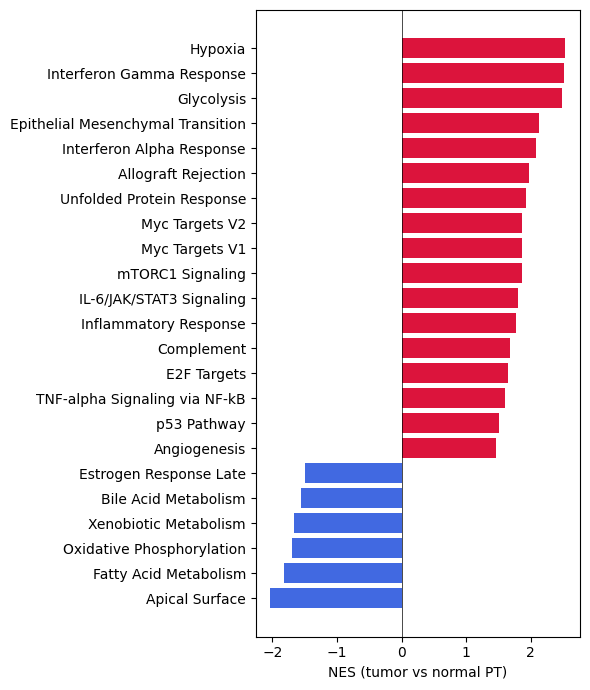

23 sets with FDR < 0.05


In [28]:
sig = out[out['FDR q-val'] < 0.05].sort_values('NES')
colors = ['royalblue' if v < 0 else 'crimson' for v in sig['NES']]

plt.figure(figsize=(6, 7))
plt.barh(sig['Term'], sig['NES'], color=colors)
plt.axvline(0, c='k', lw=0.5)
plt.xlabel('NES (tumor vs normal PT)')
plt.tight_layout()
plt.savefig('GSEA_hallmark.png', dpi=200)
plt.show()
print(len(sig), "sets with FDR < 0.05")

**GSEA on the paired analysis** and comparison with the main result (direction and significance).

In [29]:
rnk_p = res_p['stat'].dropna().sort_values(ascending=False)

pre_p = gp.prerank(rnk=rnk_p, gene_sets='MSigDB_Hallmark_2020',
                   permutation_num=1000, min_size=15, max_size=500,
                   seed=0, outdir=None, verbose=False)

out_p = pre_p.res2d.copy()
out_p['NES'] = out_p['NES'].astype(float)
out_p['FDR q-val'] = out_p['FDR q-val'].astype(float)

cmp_ = out[['Term', 'NES', 'FDR q-val']].merge(
    out_p[['Term', 'NES', 'FDR q-val']], on='Term', suffixes=('_main', '_paired'))

print("NES correlation:", round(cmp_['NES_main'].corr(cmp_['NES_paired']), 2))

s = cmp_[cmp_['FDR q-val_main'] < 0.05]
print("significant in main:", len(s))
print("of those, also significant in paired:", (s['FDR q-val_paired'] < 0.05).sum())
print("of those, with the same NES sign:", (np.sign(s['NES_main']) == np.sign(s['NES_paired'])).sum())

print(s.sort_values('NES_main').round(3).to_string(index=False))

NES correlation: 0.84
significant in main: 23
of those, also significant in paired: 16
of those, with the same NES sign: 23
                             Term  NES_main  FDR q-val_main  NES_paired  FDR q-val_paired
                   Apical Surface    -2.029           0.001      -1.981             0.001
            Fatty Acid Metabolism    -1.824           0.003      -1.264             0.257
        Oxidative Phosphorylation    -1.701           0.008      -1.200             0.300
            Xenobiotic Metabolism    -1.664           0.009      -1.413             0.200
             Bile Acid Metabolism    -1.560           0.022      -1.072             0.453
           Estrogen Response Late    -1.493           0.033      -1.728             0.010
                     Angiogenesis     1.460           0.031       1.285             0.112
                      p53 Pathway     1.511           0.021       1.405             0.050
    TNF-alpha Signaling via NF-kB     1.607           0.008       

## Package versions

Run this cell and add the output to the README for reproducibility.

In [ ]:
import sys, importlib.metadata as md
print('python', sys.version.split()[0])
for p in ['scanpy','anndata','scrublet','harmonypy','leidenalg','gseapy','pydeseq2','pandas','numpy','matplotlib']:
    try:
        print(p, md.version(p))
    except Exception as e:
        print(p, 'not found')